# Spotify Music Popularity Prediction (Regression Project)

**Goal:** predict a track's `popularity` score (0-100) from its audio features (danceability, energy, loudness, tempo, valence ...) and genre.

**Data:** Kaggle *Spotify Tracks Dataset* (maharshipandya). The notebook uses `spotify_tracks.csv` if it is in the same folder, otherwise downloads it automatically with `kagglehub`.
If both fail it falls back to synthetic data (a warning is printed) - do not submit results from synthetic data.

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy requests beautifulsoup4

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------- ----------------------- 3.9/9.8 MB 19.5 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.8 MB 22.7 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 21.9 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   --------------- ------------------------ 5.0/12.7 MB 23.9 MB/s eta 0:00:01
   -------------------------------- ------- 10.2/12.7 MB 25.0 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 24.4 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----------------- ---------------------- 4.2/9.5 MB 20.1 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 21.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 20.9 MB/s  0:00:00
   ----------------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Step 1: Import Required Libraries

import os
import glob
import shutil
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


# Step 2: Load Dataset

# Put the Kaggle file in the same folder as this notebook, or change this path,
# e.g. r"C:\Users\admin\Downloads\spotify_tracks.csv"
DATA_PATH = "dataset.csv"


def download_from_kaggle():
    """Download the dataset from Kaggle (needs: pip install kagglehub)."""
    import kagglehub
    folder = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
    csv_file = glob.glob(os.path.join(folder, "*.csv"))[0]
    shutil.copy(csv_file, DATA_PATH)


def make_synthetic_spotify(n=6000, seed=42):
    """Fake data with the same columns as the Kaggle file. Used ONLY if the real data cannot be loaded."""
    rng = np.random.default_rng(seed)
    genres = ["pop", "rock", "hip-hop", "edm", "jazz", "classical", "country", "latin", "r-n-b", "indie"]
    boost = dict(zip(genres, [14, 6, 12, 5, -4, -10, 2, 10, 7, 0]))
    d = pd.DataFrame({
        "Unnamed: 0": np.arange(n),
        "track_id": [f"id{i}" for i in range(n)],
        "artists": rng.choice([f"Artist {i}" for i in range(400)], n),
        "album_name": rng.choice([f"Album {i}" for i in range(900)], n),
        "track_name": [f"Track {i}" for i in range(n)],
        "duration_ms": np.clip(rng.normal(230000, 60000, n), 60000, 600000).astype(int),
        "explicit": rng.choice([True, False], n, p=[0.15, 0.85]),
        "danceability": np.clip(rng.normal(0.58, 0.17, n), 0, 1),
        "energy": np.clip(rng.normal(0.62, 0.24, n), 0, 1),
        "key": rng.integers(0, 12, n),
        "loudness": np.clip(rng.normal(-8, 4, n), -35, 1),
        "mode": rng.choice([0, 1], n, p=[0.35, 0.65]),
        "speechiness": np.clip(rng.exponential(0.09, n), 0, 1),
        "acousticness": np.clip(rng.beta(0.6, 1.2, n), 0, 1),
        "instrumentalness": np.clip(rng.beta(0.2, 2.5, n), 0, 1),
        "liveness": np.clip(rng.exponential(0.19, n), 0, 1),
        "valence": np.clip(rng.normal(0.5, 0.25, n), 0, 1),
        "tempo": np.clip(rng.normal(121, 29, n), 40, 220),
        "time_signature": rng.choice([3, 4, 5], n, p=[0.07, 0.9, 0.03]),
        "track_genre": rng.choice(genres, n),
    })
    pop = (30 + 22 * d.danceability + 14 * d.energy + 0.9 * d.loudness - 12 * d.instrumentalness
           - 8 * d.acousticness + 5 * d.explicit + d.track_genre.map(boost) + rng.normal(0, 9, n))
    d["popularity"] = np.clip(pop, 0, 100).round().astype(int)
    return d


if not os.path.exists(DATA_PATH):
    try:
        download_from_kaggle()
        print("Dataset downloaded automatically from Kaggle.")
    except Exception as e:
        print("Automatic Kaggle download failed:", str(e)[:150])

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print("Dataset loaded successfully (real Kaggle data).")
else:
    df = make_synthetic_spotify()
    print("WARNING: using SYNTHETIC data. Download the real file and re-run before submitting.")

print("Dataset shape:", df.shape)

display(df.head())


# Step 3: Inspect Dataset

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

print("\nNumber of Duplicate track_id values (same song listed under several genres):")
print(df["track_id"].duplicated().sum())


# Step 4: Data Cleaning

df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])   # index column in the Kaggle file

df = df.drop_duplicates()

# the same track can appear several times (once per genre); keep one copy so that
# the same song cannot end up in both the training set and the test set
df = df.drop_duplicates(subset="track_id")

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

for column in ["artists", "album_name", "track_name"]:
    df[column] = df[column].fillna("Unknown")

df["explicit"] = df["explicit"].astype(int)          # True/False -> 1/0

print("Data cleaning completed.")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(df.duplicated().sum())

print("\nCleaned Dataset Shape:", df.shape)

Libraries imported successfully.
Dataset loaded successfully (real Kaggle data).
Dataset shape: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness  


Column: track_id
track_id
5SuOikwiRyPMVoIQDJUgSV    1
4qPNDBW1i3p13qLCt0Ki3A    1
1iJBSr7s7jYXzM8EGcbK5b    1
6lfxq3CG4xtTiEg7opyCyx    1
5vjLSffimiIP26QG5WcN2K    1
01MVOl9KtVTNfFiBU9I7dc    1
6Vc5wAMmXdKIAM7WUoEb7N    1
1EzrEOXmMH3G43AXT1y7pA    1
0IktbUcnAGrvD03AWnz3Q8    1
7k9GuJYLp2AzqokyEdwEw2    1
Name: count, dtype: int64

Column: artists
artists
George Jones         260
my little airport    171
The Beatles          149
BTS                  143
Håkan Hellström      141
Glee Cast            139
Hank Williams        136
Linkin Park          133
Scooter              130
OneRepublic          124
Name: count, dtype: int64

Column: album_name
album_name
The Complete Hank Williams     110
Greatest Hits                   77
Mozart: A Night of Classics     75
Alternative Christmas 2022      73
Hans Zimmer: Epic Scores        68
Mozart - All Day Classics       68
Classical Christmas             61
Mozart - Inspiring Classics     58
Best Of Karneval                58
Karneval 2022 100%  

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,89741.000000,8.974100e+04,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000,89741.000000
mean,33.198438,2.291418e+05,0.085847,0.562166,0.634458,5.283549,-8.499004,0.636966,0.087442,0.328289,0.173413,0.216970,0.469477,122.058316,3.897427
std,20.580824,1.129477e+05,0.280140,0.176691,0.256605,3.559897,5.221490,0.480877,0.113277,0.338321,0.323848,0.194884,0.262864,30.117532,0.453435
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,1.730400e+05,0.000000,0.450000,0.457000,2.000000,-10.322000,0.000000,0.036000,0.017100,0.000000,0.098200,0.249000,99.264000,4.000000
50%,33.000000,2.132930e+05,0.000000,0.576000,0.676000,5.000000,-7.185000,1.000000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,4.000000
75%,49.000000,2.642930e+05,0.000000,0.692000,0.853000,8.000000,-5.108000,1.000000,0.085900,0.625000,0.097600,0.279000,0.682000,140.077000,4.000000
max,100.000000,5.237295e+06,1.000000,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


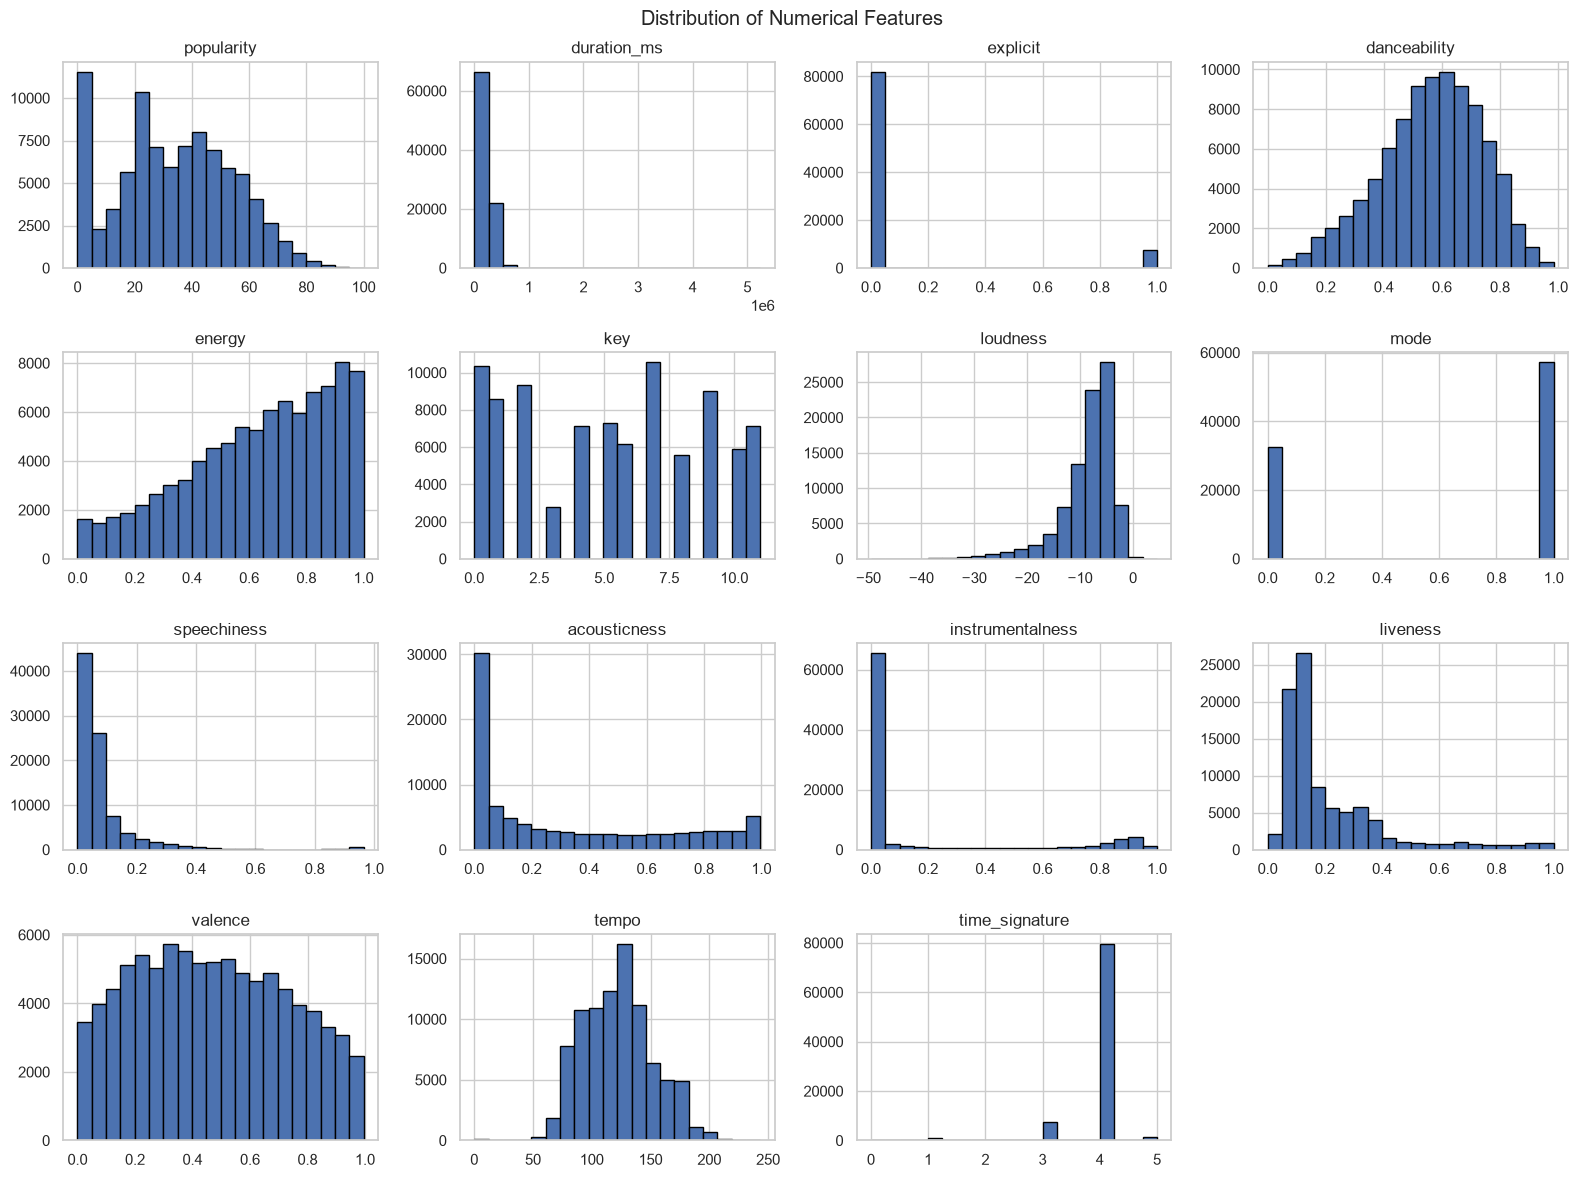

Target Variable Summary:
count    89741.000000
mean        33.198438
std         20.580824
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64

Number of tracks with popularity = 0: 9448


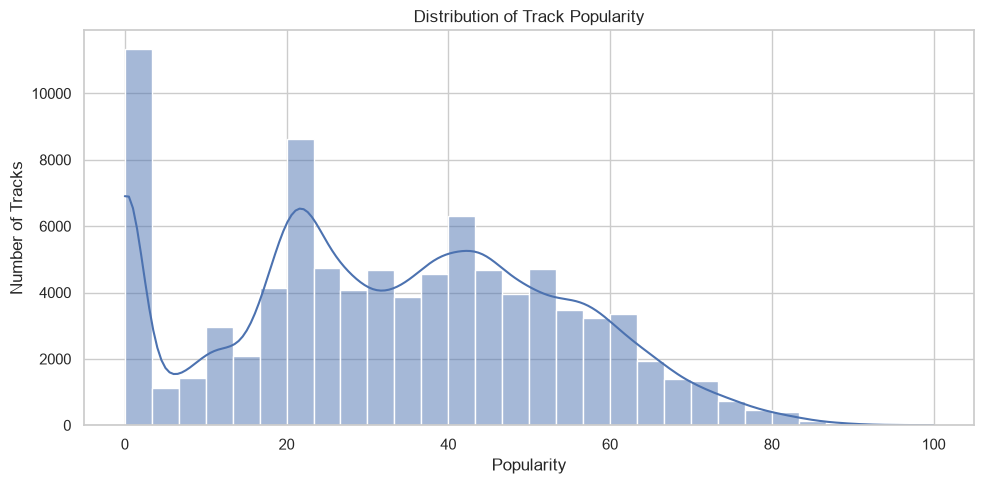

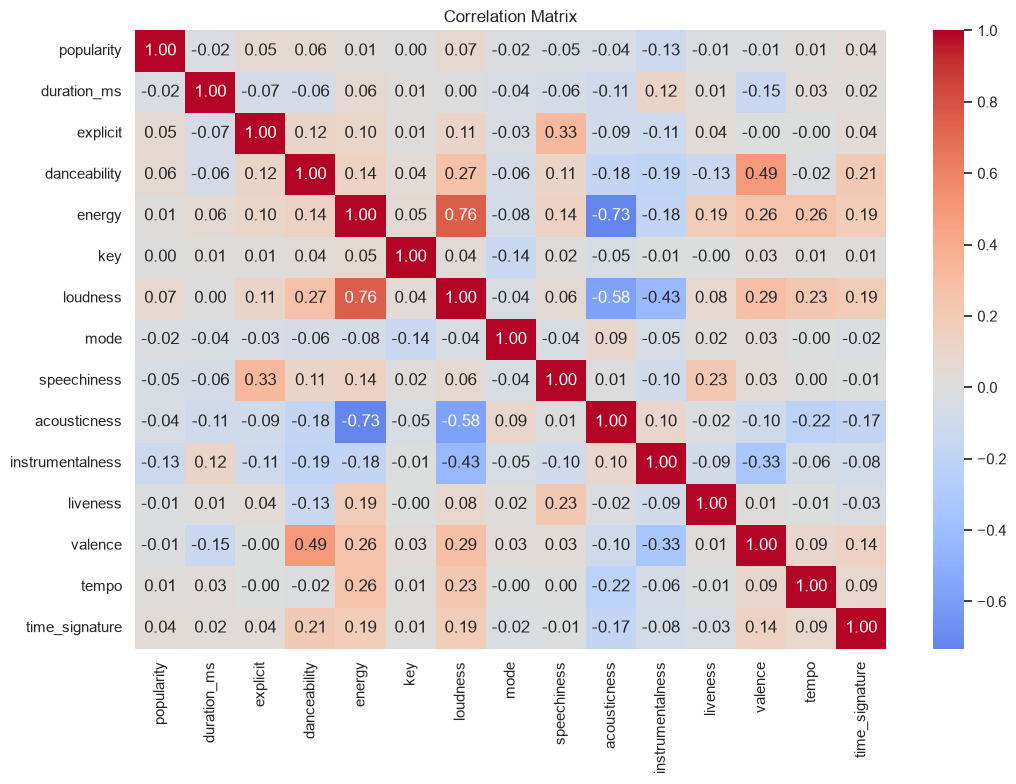

Correlation with popularity:
loudness            0.072
danceability        0.064
explicit            0.055
time_signature      0.037
energy              0.014
tempo               0.007
key                 0.003
valence            -0.012
liveness           -0.014
mode               -0.016
duration_ms        -0.023
acousticness       -0.039
speechiness        -0.047
instrumentalness   -0.127
Name: popularity, dtype: float64


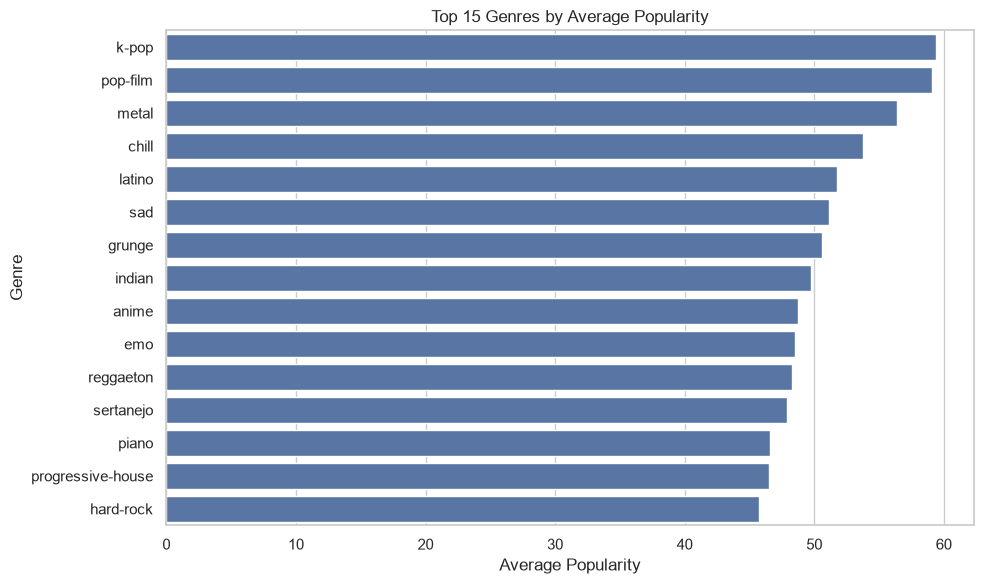

In [5]:
# Step 5: Explore Categorical Columns

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts().head(10))


# Step 6: Statistical Analysis

print("Statistical Summary:")
display(df.describe())


# Step 7: Numerical Feature Distribution

numerical_columns = df.select_dtypes(include=np.number).columns

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


# Step 8: Target Variable Analysis

target = "popularity"

print("Target Variable Summary:")
print(df[target].describe())

print("\nNumber of tracks with popularity = 0:", (df[target] == 0).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=target,
    bins=30,
    kde=True
)

plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Tracks")

plt.tight_layout()
plt.show()


# Step 8A: Correlation of Audio Features with Popularity

correlation = df[numerical_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with popularity:")
print(correlation[target].drop(target).sort_values(ascending=False).round(3))


# Step 8B: Average Popularity by Genre (top 15)

genre_popularity = (
    df.groupby("track_genre")[target]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_popularity.values,
    y=genre_popularity.index
)

plt.title("Top 15 Genres by Average Popularity")
plt.xlabel("Average Popularity")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

In [6]:
# Step 9: Separate Features and Target

X = df.drop(
    columns=["track_id", "artists", "album_name", "track_name", "popularity"]
)

y = df["popularity"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())


# Step 10: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


# Step 11: Identify Feature Types

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# Step 12: Create Preprocessor

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully.")

Input Features Shape: (89741, 15)
Target Shape: (89741,)

Input Features:
['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']
Training Features: (71792, 15)
Testing Features: (17949, 15)
Training Target: (71792,)
Testing Target: (17949,)
Numerical Features:
['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

Categorical Features:
['track_genre']
Preprocessor created successfully.


In [7]:
# Step 13: Linear Regression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test, linear_predictions
)

print("Linear Regression Results")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R2 Score:", round(linear_r2, 4))



# Step 14: Decision Tree Regression

decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

decision_tree_model.fit(X_train, y_train)

tree_predictions = decision_tree_model.predict(X_test)

tree_mae = mean_absolute_error(
    y_test, tree_predictions
)

tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_predictions)
)

tree_r2 = r2_score(
    y_test, tree_predictions
)

print("Decision Tree Regression Results")
print("MAE:", round(tree_mae, 4))
print("RMSE:", round(tree_rmse, 4))
print("R2 Score:", round(tree_r2, 4))



# Step 15: Random Forest Regression

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test, rf_predictions
)

print("Original Random Forest Results")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))


# Step 16: Model Comparison

comparison_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],
    "R2 Score": [
        linear_r2,
        tree_r2,
        rf_r2
    ]
})

print("Regression Model Comparison:")
display(comparison_results.round(4))

Linear Regression Results
MAE: 17.0486
RMSE: 20.3656
R2 Score: 0.007
Decision Tree Regression Results
MAE: 12.8814
RMSE: 20.3154
R2 Score: 0.0119
Original Random Forest Results
MAE: 10.0193
RMSE: 14.8896
R2 Score: 0.4692
Regression Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,17.0486,20.3656,0.0070
1,Decision Tree Regression,12.8814,20.3154,0.0119
2,Random Forest Regression,10.0193,14.8896,0.4692


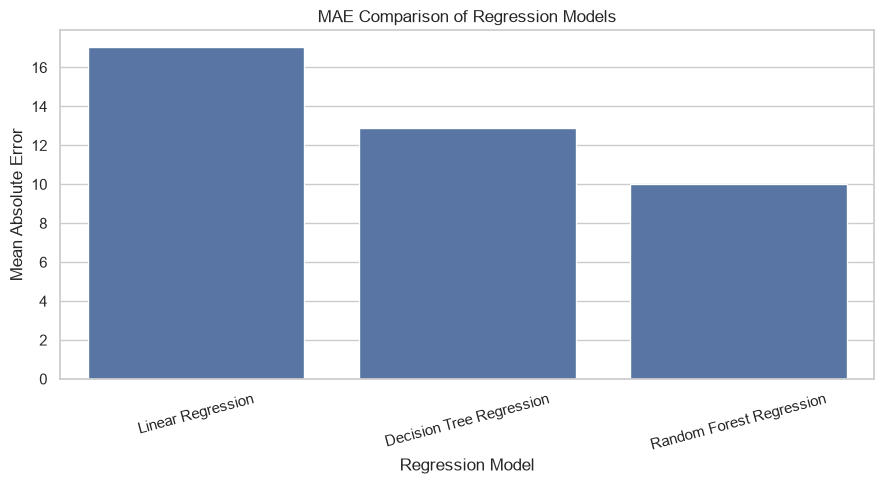

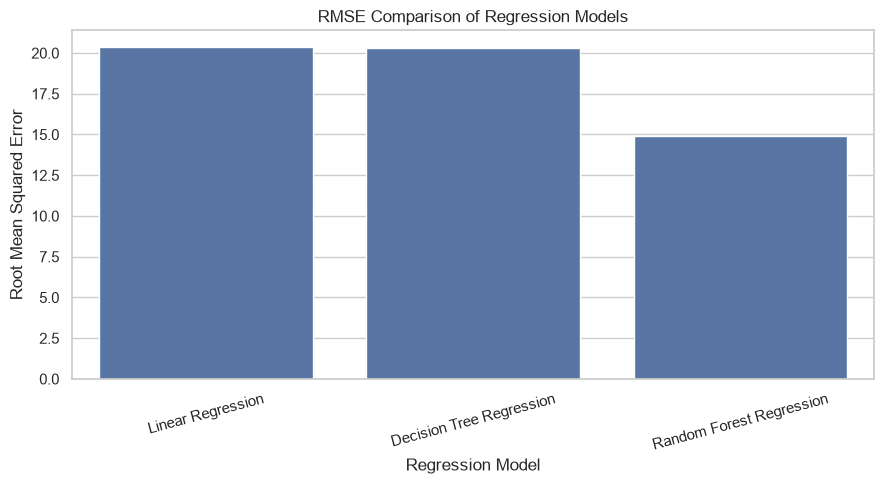

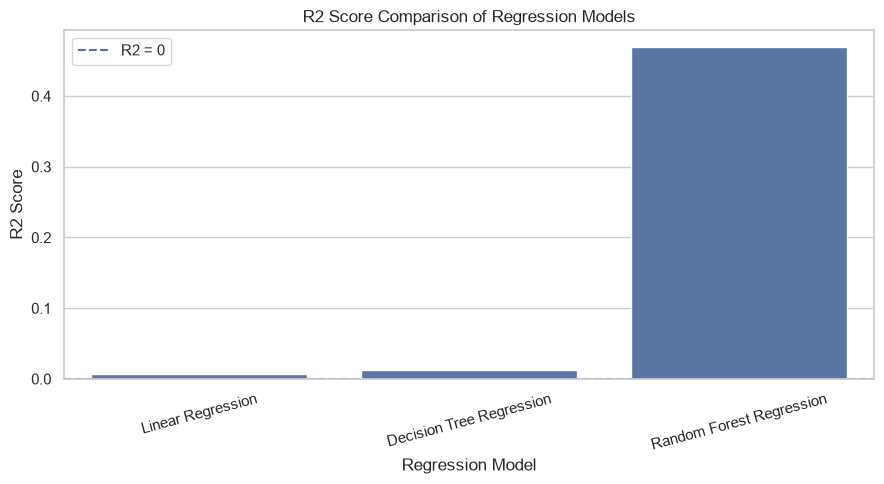

Best Model Among the Three:
Random Forest Regression

MAE: 10.0193
RMSE: 14.8896
R2 Score: 0.4692


In [8]:
# Step 17: MAE Comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_results,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()



# Step 18: RMSE Comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_results,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()



# Step 19: R2 Score Comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_results,
    x="Model",
    y="R2 Score"
)

plt.axhline(
    y=0,
    linestyle="--",
    label="R2 = 0"
)

plt.title("R2 Score Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.legend()

plt.tight_layout()
plt.show()



# Step 20: Identify Best Model

best_model_row = comparison_results.loc[
    comparison_results["R2 Score"].idxmax()
]

print("Best Model Among the Three:")
print(best_model_row["Model"])

print("\nMAE:", round(best_model_row["MAE"], 4))
print("RMSE:", round(best_model_row["RMSE"], 4))
print("R2 Score:", round(best_model_row["R2 Score"], 4))

In [9]:
# Step 21: Training vs Testing Performance

models_dict = {
    "Linear Regression": linear_model,
    "Decision Tree Regression": decision_tree_model,
    "Random Forest Regression": random_forest_model
}

overfitting_results = []

for name, model in models_dict.items():

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_mae = mean_absolute_error(
        y_train, train_predictions
    )

    test_mae = mean_absolute_error(
        y_test, test_predictions
    )

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    train_r2 = r2_score(
        y_train, train_predictions
    )

    test_r2 = r2_score(
        y_test, test_predictions
    )

    overfitting_results.append({
        "Model": name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R2": train_r2,
        "Test R2": test_r2
    })

overfitting_table = pd.DataFrame(overfitting_results)

print("Training vs Testing Performance:")
display(overfitting_table.round(4))


# Step 22: Tuned Random Forest

tuned_random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    ))
])

tuned_random_forest.fit(X_train, y_train)

tuned_train_predictions = tuned_random_forest.predict(X_train)
tuned_test_predictions = tuned_random_forest.predict(X_test)

print("Tuned Random Forest Performance")

print("\nTraining Performance")

print(
    "MAE:",
    round(
        mean_absolute_error(y_train, tuned_train_predictions),
        4
    )
)

print(
    "RMSE:",
    round(
        np.sqrt(
            mean_squared_error(y_train, tuned_train_predictions)
        ),
        4
    )
)

print(
    "R2 Score:",
    round(
        r2_score(y_train, tuned_train_predictions),
        4
    )
)

print("\nTesting Performance")

print(
    "MAE:",
    round(
        mean_absolute_error(y_test, tuned_test_predictions),
        4
    )
)

print(
    "RMSE:",
    round(
        np.sqrt(
            mean_squared_error(y_test, tuned_test_predictions)
        ),
        4
    )
)

print(
    "R2 Score:",
    round(
        r2_score(y_test, tuned_test_predictions),
        4
    )
)


# Step 23: Original vs Tuned Random Forest

rf_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Train MAE": [
        mean_absolute_error(y_train, random_forest_model.predict(X_train)),
        mean_absolute_error(y_train, tuned_random_forest.predict(X_train))
    ],
    "Test MAE": [
        mean_absolute_error(y_test, random_forest_model.predict(X_test)),
        mean_absolute_error(y_test, tuned_random_forest.predict(X_test))
    ],
    "Train RMSE": [
        np.sqrt(mean_squared_error(y_train, random_forest_model.predict(X_train))),
        np.sqrt(mean_squared_error(y_train, tuned_random_forest.predict(X_train)))
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, random_forest_model.predict(X_test))),
        np.sqrt(mean_squared_error(y_test, tuned_random_forest.predict(X_test)))
    ],
    "Train R2": [
        r2_score(y_train, random_forest_model.predict(X_train)),
        r2_score(y_train, tuned_random_forest.predict(X_train))
    ],
    "Test R2": [
        r2_score(y_test, random_forest_model.predict(X_test)),
        r2_score(y_test, tuned_random_forest.predict(X_test))
    ]
})

print("Original vs Tuned Random Forest:")
display(rf_comparison.round(4))


# Step 24: Cross-Validation

models_for_cv = {
    "Original Random Forest": random_forest_model,
    "Tuned Random Forest": tuned_random_forest
}

cv_results = []

for name, model in models_for_cv.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV R2 Mean": scores.mean(),
        "CV R2 Std": scores.std()
    })

    print("\n", name)
    print("Cross-validation R2 scores:", scores.round(4))
    print("Mean R2:", round(scores.mean(), 4))
    print("Standard Deviation:", round(scores.std(), 4))

cv_comparison = pd.DataFrame(cv_results)

print("\nCross-Validation Comparison:")
display(cv_comparison.round(4))

Training vs Testing Performance:


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Linear Regression,17.1966,17.0486,20.5551,20.3656,0.0059,0.0070
1,Decision Tree Regression,0.3739,12.8814,3.1063,20.3154,0.9773,0.0119
2,Random Forest Regression,3.9283,10.0193,6.2031,14.8896,0.9095,0.4692


Tuned Random Forest Performance

Training Performance
MAE: 14.3922
RMSE: 18.2959
R2 Score: 0.2124

Testing Performance
MAE: 14.5289
RMSE: 18.3751
R2 Score: 0.1916
Original vs Tuned Random Forest:


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Original Random Forest,3.9283,10.0193,6.2031,14.8896,0.9095,0.4692
1,Tuned Random Forest,14.3922,14.5289,18.2959,18.3751,0.2124,0.1916



 Original Random Forest
Cross-validation R2 scores: [0.4672 0.4607 0.471  0.4527 0.4463]
Mean R2: 0.4596
Standard Deviation: 0.0091

 Tuned Random Forest
Cross-validation R2 scores: [0.199  0.1918 0.1993 0.1985 0.1973]
Mean R2: 0.1972
Standard Deviation: 0.0028

Cross-Validation Comparison:


,Model,CV R2 Mean,CV R2 Std
0,Original Random Forest,0.4596,0.0091
1,Tuned Random Forest,0.1972,0.0028


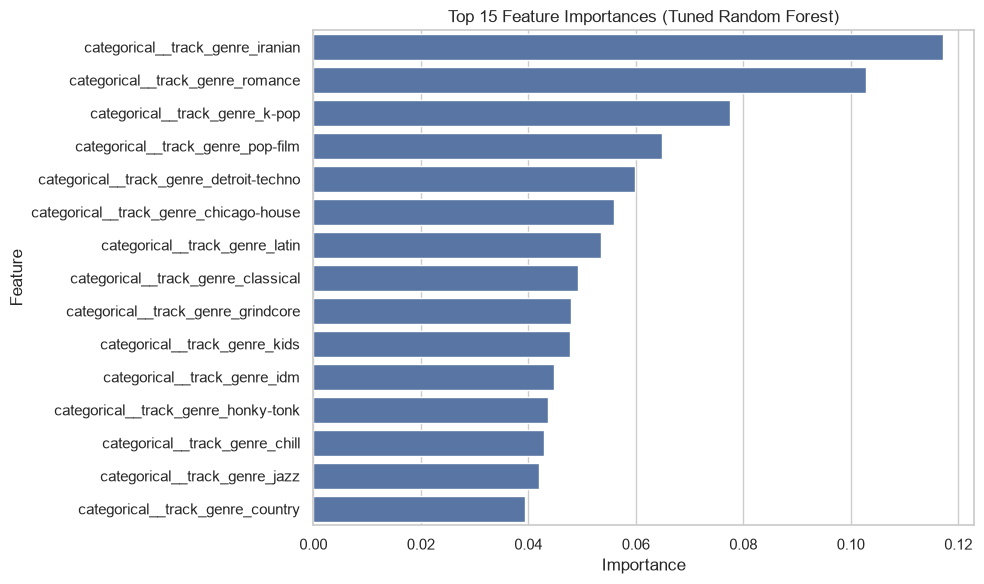

Predicted popularity of the new song: 35.4 / 100
Cleaned dataset saved successfully as: Spotify_Data_Cleaned.csv
FINAL REGRESSION PROJECT SUMMARY

Dataset Information
Total Rows: 89741
Total Columns: 20

Original Model Comparison


,Model,MAE,RMSE,R2 Score
0,Linear Regression,17.0486,20.3656,0.0070
1,Decision Tree Regression,12.8814,20.3154,0.0119
2,Random Forest Regression,10.0193,14.8896,0.4692



Original vs Tuned Random Forest


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Original Random Forest,3.9283,10.0193,6.2031,14.8896,0.9095,0.4692
1,Tuned Random Forest,14.3922,14.5289,18.2959,18.3751,0.2124,0.1916



Cross-Validation Results


,Model,CV R2 Mean,CV R2 Std
0,Original Random Forest,0.4596,0.0091
1,Tuned Random Forest,0.1972,0.0028



Best Original Model Based on Test R2:
Random Forest Regression

Best Original Model Metrics:
MAE: 10.0193
RMSE: 14.8896
R2 Score: 0.4692

Project completed successfully.


In [10]:
# Step 25: Feature Importance (what makes a song popular?)

rf_step = tuned_random_forest.named_steps["model"]
feature_names = tuned_random_forest.named_steps["preprocessor"].get_feature_names_out()

importance = pd.Series(
    rf_step.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=importance.values,
    y=importance.index
)

plt.title("Top 15 Feature Importances (Tuned Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# Step 26: Predict Popularity of a New Song

new_song = pd.DataFrame([{
    "duration_ms": 210000,
    "explicit": 0,
    "danceability": 0.80,
    "energy": 0.75,
    "key": 5,
    "loudness": -5.0,
    "mode": 1,
    "speechiness": 0.06,
    "acousticness": 0.10,
    "instrumentalness": 0.0,
    "liveness": 0.12,
    "valence": 0.70,
    "tempo": 118,
    "time_signature": 4,
    "track_genre": df["track_genre"].mode()[0]
}])[X.columns]

predicted = tuned_random_forest.predict(new_song)[0]

print("Predicted popularity of the new song:", round(predicted, 1), "/ 100")


# Step 27: Save Cleaned Dataset

output_file = "Spotify_Data_Cleaned.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully as:", output_file)



# Step 28: Final Summary

print("=" * 55)
print("FINAL REGRESSION PROJECT SUMMARY")
print("=" * 55)

print("\nDataset Information")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nOriginal Model Comparison")
display(comparison_results.round(4))

print("\nOriginal vs Tuned Random Forest")
display(rf_comparison.round(4))

print("\nCross-Validation Results")
display(cv_comparison.round(4))

print("\nBest Original Model Based on Test R2:")
print(best_model_row["Model"])

print("\nBest Original Model Metrics:")
print("MAE:", round(best_model_row["MAE"], 4))
print("RMSE:", round(best_model_row["RMSE"], 4))
print("R2 Score:", round(best_model_row["R2 Score"], 4))

print("\nProject completed successfully.")